In [1]:
# STEP 1: LOAD CUSTOMER DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("customer_segmentation.csv")

print("CUSTOMER BUSINESS INTELLIGENCE ANALYSIS")
print("=" * 55)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

CUSTOMER BUSINESS INTELLIGENCE ANALYSIS
Dataset shape: (2240, 29)

Column names:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

First 5 rows:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [2]:
# STEP 2: DATA QUALITY CHECK

print("=" * 60)
print("CUSTOMER DATA QUALITY CHECK")
print("=" * 60)

print("\n1. MISSING VALUES")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n2. TOTAL MISSING VALUES")
print(df.isnull().sum().sum())

print("\n3. DUPLICATE ROWS")
print(df.duplicated().sum())

print("\n4. DATA TYPES")
print(df.dtypes)

print("\n5. DATASET SUMMARY")
print(df.describe().round(2))

CUSTOMER DATA QUALITY CHECK

1. MISSING VALUES
Income    24
dtype: int64

2. TOTAL MISSING VALUES
24

3. DUPLICATE ROWS
0

4. DATA TYPES
ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                i

In [3]:
# STEP 3: INVESTIGATE UNUSUAL CUSTOMER RECORDS

print("=" * 60)
print("UNUSUAL CUSTOMER RECORD INVESTIGATION")
print("=" * 60)

print("\n1. CUSTOMERS WITH MISSING INCOME")
display(df[df["Income"].isnull()].head(10))

print("\n2. CUSTOMERS WITH EXTREMELY HIGH INCOME")
display(
    df[df["Income"] > 200000][
        ["ID", "Year_Birth", "Education",
         "Marital_Status", "Income"]
    ]
)

print("\n3. CUSTOMERS WITH UNUSUAL BIRTH YEARS")
display(
    df[df["Year_Birth"] < 1940][
        ["ID", "Year_Birth", "Education",
         "Marital_Status", "Income"]
    ].sort_values("Year_Birth")
)

UNUSUAL CUSTOMER RECORD INVESTIGATION

1. CUSTOMERS WITH MISSING INCOME


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
10,1994,1983,Graduation,Married,NaN,1,0,15-11-2013,11,5,...,7,0,0,0,0,0,0,3,11,0
27,5255,1986,Graduation,Single,NaN,1,0,20-02-2013,19,5,...,1,0,0,0,0,0,0,3,11,0
43,7281,1959,PhD,Single,NaN,0,0,05-11-2013,80,81,...,2,0,0,0,0,0,0,3,11,0
48,7244,1951,Graduation,Single,NaN,2,1,01-01-2014,96,48,...,6,0,0,0,0,0,0,3,11,0
58,8557,1982,Graduation,Single,NaN,1,0,17-06-2013,57,11,...,6,0,0,0,0,0,0,3,11,0
71,10629,1973,2n Cycle,Married,NaN,1,0,14-09-2012,25,25,...,8,0,0,0,0,0,0,3,11,0
90,8996,1957,PhD,Married,NaN,2,1,19-11-2012,4,230,...,9,0,0,0,0,0,0,3,11,0
91,9235,1957,Graduation,Single,NaN,1,1,27-05-2014,45,7,...,7,0,0,0,0,0,0,3,11,0
92,5798,1973,Master,Together,NaN,0,0,23-11-2013,87,445,...,1,0,0,0,0,0,0,3,11,0
128,8268,1961,PhD,Married,NaN,0,1,11-07-2013,23,352,...,6,0,0,0,0,0,0,3,11,0



2. CUSTOMERS WITH EXTREMELY HIGH INCOME


,ID,Year_Birth,Education,Marital_Status,Income
2233,9432,1977,Graduation,Together,666666.0



3. CUSTOMERS WITH UNUSUAL BIRTH YEARS


,ID,Year_Birth,Education,Marital_Status,Income
239,11004,1893,2n Cycle,Single,60182.0
339,1150,1899,PhD,Together,83532.0
192,7829,1900,2n Cycle,Divorced,36640.0


In [4]:
# STEP 4: CREATE CUSTOMER BUSINESS METRICS

# Create a separate working copy
customer_df = df.copy()

# Total spending across six product categories
spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

customer_df["Total_Spending"] = (
    customer_df[spending_columns].sum(axis=1)
)

# Total purchases across three channels
purchase_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

customer_df["Total_Purchases"] = (
    customer_df[purchase_columns].sum(axis=1)
)

# Total previous campaigns accepted
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5"
]

customer_df["Campaigns_Accepted"] = (
    customer_df[campaign_columns].sum(axis=1)
)

print("CUSTOMER BUSINESS METRICS CREATED")
print("=" * 55)

print("\nFirst 5 customers:")
display(
    customer_df[
        ["ID", "Income", "Total_Spending",
         "Total_Purchases", "Campaigns_Accepted"]
    ].head()
)

print("\nOverall business metrics:")
print(
    customer_df[
        ["Total_Spending", "Total_Purchases",
         "Campaigns_Accepted"]
    ].describe().round(2)
)

CUSTOMER BUSINESS METRICS CREATED

First 5 customers:


,ID,Income,Total_Spending,Total_Purchases,Campaigns_Accepted
0,5524,58138.0,1617,22,0
1,2174,46344.0,27,4,0
2,4141,71613.0,776,20,0
3,6182,26646.0,53,6,0
4,5324,58293.0,422,14,0



Overall business metrics:
       Total_Spending  Total_Purchases  Campaigns_Accepted
count         2240.00          2240.00             2240.00
mean           605.80            12.54                0.30
std            602.25             7.21                0.68
min              5.00             0.00                0.00
25%             68.75             6.00                0.00
50%            396.00            12.00                0.00
75%           1045.50            18.00                0.00
max           2525.00            32.00                4.00


Three early observations:
- Customer spending varies considerably: the average is 605.80, while the median is 396.
- Campaign engagement is low: at least half of customers accepted zero previous campaigns.
- Purchasing activity varies: customers made between 0 and 32 purchases across the three channels.

Three early observations:
- Customer spending varies considerably: the average is 605.80, while the median is 396.
- Campaign engagement is low: at least half of customers accepted zero previous campaigns.
- Purchasing activity varies: customers made between 0 and 32 purchases across the three channels.

In [6]:
# STEP 5: APPLY EXISTING CUSTOMER SEGMENTATION MODEL

import joblib

# Recreate the same age calculation used in the original model
customer_df["Age"] = 2025 - customer_df["Year_Birth"]

# Use the exact original model features and order
features = [
    "Age",
    "Income",
    "Total_Spending",
    "NumWebPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Recency"
]

# Load existing saved model and scaler
kmeans = joblib.load("kmeans_model.pkl")
scaler = joblib.load("scaler.pkl")

# Identify customers with complete model features
valid_mask = customer_df[features].notna().all(axis=1)

# Scale and predict using the existing model
X_valid = customer_df.loc[valid_mask, features]
X_scaled = scaler.transform(X_valid)

customer_df["Cluster"] = np.nan

customer_df.loc[valid_mask, "Cluster"] = (
    kmeans.predict(X_scaled)
)

print("EXISTING CUSTOMER SEGMENTS APPLIED")
print("=" * 55)

print("Total customers:", len(customer_df))
print("Customers assigned to clusters:", valid_mask.sum())
print("Customers without cluster assignment:", (~valid_mask).sum())

print("\nCustomer count by cluster:")
print(customer_df["Cluster"].value_counts().sort_index())

EXISTING CUSTOMER SEGMENTS APPLIED
Total customers: 2240
Customers assigned to clusters: 2216
Customers without cluster assignment: 24

Customer count by cluster:
Cluster
0.0    377
1.0    457
2.0    330
3.0    290
4.0    450
5.0    312
Name: count, dtype: int64


In [7]:
# STEP 6: CUSTOMER SEGMENT BUSINESS PERFORMANCE

segment_performance = customer_df.groupby("Cluster").agg(
    Customer_Count=("ID", "count"),
    Average_Income=("Income", "mean"),
    Average_Spending=("Total_Spending", "mean"),
    Total_Spending=("Total_Spending", "sum"),
    Average_Purchases=("Total_Purchases", "mean"),
    Average_Web_Purchases=("NumWebPurchases", "mean"),
    Average_Store_Purchases=("NumStorePurchases", "mean"),
    Average_Web_Visits=("NumWebVisitsMonth", "mean"),
    Average_Recency=("Recency", "mean"),
    Average_Campaigns_Accepted=("Campaigns_Accepted", "mean")
)

segment_performance["Customer_Share_Pct"] = (
    segment_performance["Customer_Count"]
    / segment_performance["Customer_Count"].sum() * 100
)

segment_performance["Spending_Share_Pct"] = (
    segment_performance["Total_Spending"]
    / segment_performance["Total_Spending"].sum() * 100
)

print("=" * 75)
print("CUSTOMER SEGMENT BUSINESS PERFORMANCE")
print("=" * 75)

display(segment_performance.round(2))

CUSTOMER SEGMENT BUSINESS PERFORMANCE


,Customer_Count,Average_Income,Average_Spending,Total_Spending,Average_Purchases,Average_Web_Purchases,Average_Store_Purchases,Average_Web_Visits,Average_Recency,Average_Campaigns_Accepted,Customer_Share_Pct,Spending_Share_Pct
Cluster,,,,,,,,,,,,
0.0,377,33476.11,130.27,49111,6.44,2.46,3.31,7.03,76.62,0.08,17.01,3.65
1.0,457,79561.39,1371.80,626913,18.65,4.29,8.41,2.25,54.43,0.72,20.62,46.60
2.0,330,61950.47,999.33,329779,20.44,8.01,8.48,6.00,65.02,0.35,14.89,24.51
3.0,290,44533.53,189.21,54872,7.76,2.53,4.09,5.19,57.97,0.10,13.09,4.08
4.0,450,31760.38,91.36,41114,5.63,2.01,3.04,6.67,24.96,0.11,20.31,3.06
5.0,312,61376.01,780.42,243490,17.14,6.03,7.74,5.21,17.15,0.35,14.08,18.10


In [8]:
# STEP 7: VERIFY CLUSTER 5 PERFORMANCE

display(
    segment_performance.loc[[5.0]].T
)

Cluster,5.0
Customer_Count,312.000000
Average_Income,61376.009615
Average_Spending,780.416667
Total_Spending,243490.000000
Average_Purchases,17.144231
Average_Web_Purchases,6.032051
Average_Store_Purchases,7.740385
Average_Web_Visits,5.208333
Average_Recency,17.147436
Average_Campaigns_Accepted,0.349359


Key findings
1. Clusters 1 and 2 are the biggest spending segments. Together, they represent approximately 35.5% of customers but contribute 71.11% of total customer spending.
2. Cluster 5 is another valuable segment. It contributes 18.10% of spending and has the lowest average recency (17.15), indicating recent purchasing activity if Recency represents days since the last purchase.
3. Clusters 0, 3 and 4 have low average spending. They may need more targeted, cost-conscious campaigns rather than expensive promotions.
4. Cluster 4 has low recency (24.96) but very low spending. These customers have purchased recently, but their spending remains low.

In [9]:
product_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

product_segment_analysis = customer_df.groupby("Cluster")[product_columns].mean()

display(product_segment_analysis.round(2))

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Cluster,,,,,,
0.0,55.18,6.58,32.88,9.24,6.72,19.66
1.0,613.48,62.41,465.83,90.86,64.86,74.35
2.0,590.17,37.42,206.01,51.75,41.36,72.62
3.0,103.36,7.71,36.30,11.27,7.61,22.97
4.0,34.45,4.63,24.06,7.17,4.56,16.49
5.0,431.69,34.40,177.71,47.51,31.45,57.66


In [10]:
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

campaign_analysis = customer_df.groupby("Cluster")[campaign_columns].mean() * 100

display(campaign_analysis.round(2))

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
Cluster,,,,,,
0.0,0.53,0.00,6.37,1.06,0.00,4.77
1.0,21.01,3.28,7.00,13.57,27.35,25.38
2.0,6.06,2.73,6.36,14.55,5.15,14.24
3.0,0.34,0.69,4.14,4.48,0.34,4.83
4.0,0.00,0.00,10.22,0.44,0.00,15.11
5.0,7.37,1.28,8.97,11.22,6.09,22.44


Important findings
1. Cluster 1: Highest response rate (25.38%). It is also the highest-spending segment. This is a strong candidate for targeted retention and premium product campaigns.
2. Cluster 5: 22.44% response rate. Its customers are recently active and have relatively high spending.
3. Cluster 4: 15.11% response rate despite average spending of only 91.36. This is interesting: customers with low spending may still respond to campaigns.
4. Cluster 2: 14.24% response rate. Its high spending makes it worth testing targeted offers.
5. Clusters 0 and 3: Response rates are below 5%. Broad, expensive campaigns may be less attractive for these segments.

In [11]:
segment_opportunity = segment_performance[
    ["Customer_Count", "Average_Spending", "Spending_Share_Pct"]
].copy()

segment_opportunity["Response_Rate_Pct"] = (
    customer_df.groupby("Cluster")["Response"].mean() * 100
)

display(segment_opportunity.round(2))

,Customer_Count,Average_Spending,Spending_Share_Pct,Response_Rate_Pct
Cluster,,,,
0.0,377,130.27,3.65,4.77
1.0,457,1371.80,46.60,25.38
2.0,330,999.33,24.51,14.24
3.0,290,189.21,4.08,4.83
4.0,450,91.36,3.06,15.11
5.0,312,780.42,18.10,22.44


Important distinction: Cluster 4 is a potential campaign-testing opportunity, not necessarily a high-value segment. Its response rate is relatively good, but its average spending is only 91.36.

The first three segments (Clusters 1, 2 and 5) contribute 89.21% of total customer spending. They should receive particular attention in a marketing strategy.

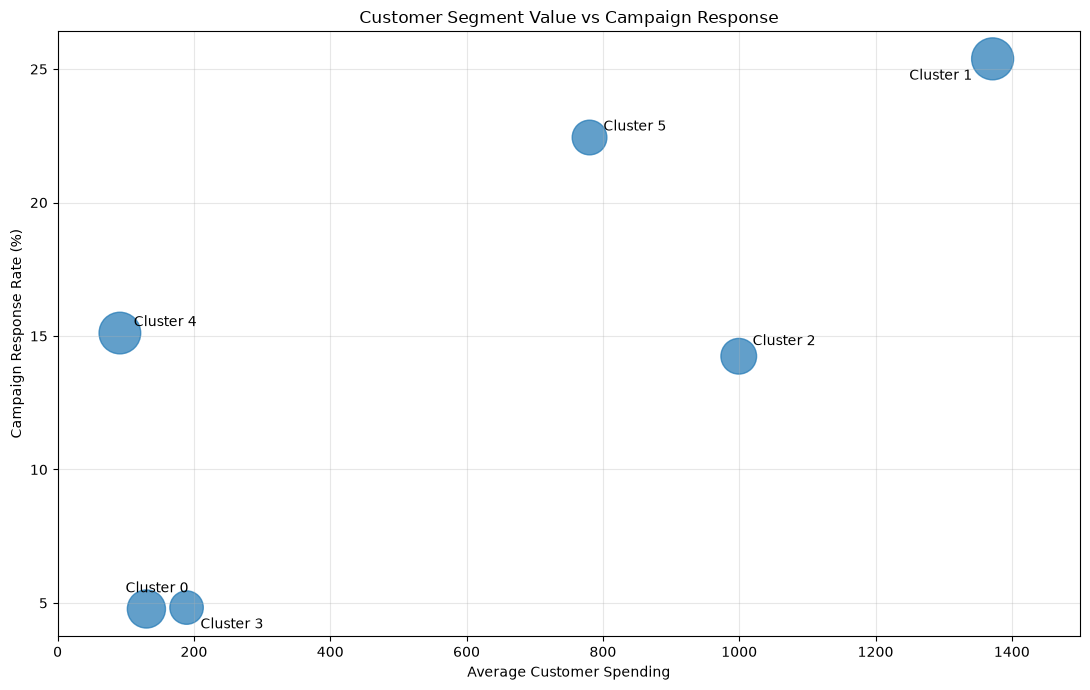

In [13]:
plt.figure(figsize=(11, 7))

plt.scatter(
    segment_opportunity["Average_Spending"],
    segment_opportunity["Response_Rate_Pct"],
    s=segment_opportunity["Customer_Count"] * 2,
    alpha=0.7
)

label_offsets = {
    0: (-15, 12),
    1: (-60, -15),
    2: (10, 8),
    3: (10, -15),
    4: (10, 5),
    5: (10, 5)
}

for cluster in segment_opportunity.index:
    plt.annotate(
        f"Cluster {int(cluster)}",
        (
            segment_opportunity.loc[cluster, "Average_Spending"],
            segment_opportunity.loc[cluster, "Response_Rate_Pct"]
        ),
        xytext=label_offsets[int(cluster)],
        textcoords="offset points"
    )

plt.title("Customer Segment Value vs Campaign Response")
plt.xlabel("Average Customer Spending")
plt.ylabel("Campaign Response Rate (%)")
plt.xlim(0, 1500)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cluster 1 is the standout segment:
- Highest average spending: 1,371.80
- Highest campaign response: 25.38%
- Largest customer group: 457 customers
- Contributes 46.60% of total spending.
Cluster 5 is another attractive segment, with 780.42 average spending and a 22.44% response rate.

Cluster 2 has high average spending (999.33), but a lower response rate (14.24%). It may need a different campaign approach.

Cluster 4 is particularly interesting: its average spending is only 91.36, but its response rate is 15.11%. This could be an opportunity to test low-cost promotions.

Clusters 0 and 3 have both low spending and low response rates.

# Executive Summary: Customer Segmentation and Marketing Intelligence

## Business Problem

A business cannot treat every customer equally when planning marketing campaigns. Marketing resources are limited, and sending the same promotion to every customer may lead to wasted campaign spending and missed opportunities.

The objective of this analysis was to identify distinct customer groups, understand their purchasing behaviour, evaluate campaign responsiveness, and recommend how marketing resources could be prioritised.

## Key Findings

- Analysed 2,240 customer records and developed six customer segments using the existing K-Means clustering model.
- Clusters 1, 2 and 5 collectively contributed **89.21% of total customer spending**.
- Cluster 1 was the strongest segment, contributing **46.60% of total spending** and recording a **25.38% campaign response rate**.
- Cluster 5 recorded a **22.44% response rate**, making it another attractive segment for retention campaigns.
- Cluster 2 contributed **24.51% of total spending**, although its response rate was lower at 14.24%.
- Cluster 4 recorded a 15.11% response rate despite having relatively low average spending, suggesting an opportunity to test cost-effective promotions.
- Clusters 0 and 3 showed both low spending and low campaign response.

## Business Recommendations

1. Prioritise Clusters 1, 2 and 5 for retention, loyalty and personalised product campaigns.
2. Develop product recommendations based on category-level purchasing patterns.
3. Test low-cost promotions for Cluster 4 before allocating larger campaign budgets.
4. Use targeted re-engagement strategies for Clusters 0 and 3.
5. Measure campaign performance through controlled experiments before scaling marketing expenditure.

## Business Value

This analysis provides a data-driven framework for customer prioritisation. Instead of treating the entire customer base as one group, the business can develop segment-specific marketing strategies based on customer spending, purchasing behaviour and observed campaign responsiveness.

## Limitations

- The analysis uses historical customer data and does not establish future purchasing behaviour.
- The dataset contains 24 missing income values.
- Customer segments are based on an existing K-Means model and depend on its selected features and preprocessing.
- Campaign response rates show historical associations, not causal campaign effectiveness.
- Profitability cannot be calculated because product costs and profit margins are not provided.
- Recommended marketing strategies require validation through controlled experiments.